In [1]:
import pandas as pd

# Base pública da IBM: clientes de uma operadora de telecom e se cancelaram (Churn)
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

bruto = pd.read_csv(URL)
bruto.to_csv("../data/raw/telco_churn.csv", index=False)

print(bruto.shape)
bruto.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
import matplotlib.pyplot as plt

dados = pd.read_csv("../data/raw/telco_churn.csv")

# 1) Qualidade dos dados
print("clientes duplicados:", dados["customerID"].duplicated().sum())
total = pd.to_numeric(dados["TotalCharges"], errors="coerce")
print("TotalCharges em branco:", total.isna().sum(),
      "| tempo de casa desses clientes:", dados.loc[total.isna(), "tenure"].unique())
# São clientes que acabaram de entrar (0 meses): ainda não pagaram nada, então o total é 0
dados["TotalCharges"] = total.fillna(0)

# 2) Alvo: 1 = cancelou
dados["churn"] = (dados["Churn"] == "Yes").astype(int)
dados = dados.drop(columns="Churn")

print(f"\nTaxa de churn: {dados['churn'].mean():.1%} ({dados['churn'].sum()} de {len(dados)} clientes)")
receita_perdida = dados.loc[dados["churn"] == 1, "MonthlyCharges"].sum()
print(f"Receita mensal dos clientes que cancelaram: US$ {receita_perdida:,.0f} "
      f"({receita_perdida / dados['MonthlyCharges'].sum():.1%} da receita mensal)")

dados.to_csv("../data/processed/clientes.csv", index=False)

clientes duplicados: 0
TotalCharges em branco: 11 | tempo de casa desses clientes: [0]

Taxa de churn: 26.5% (1869 de 7043 clientes)
Receita mensal dos clientes que cancelaram: US$ 139,131 (30.5% da receita mensal)


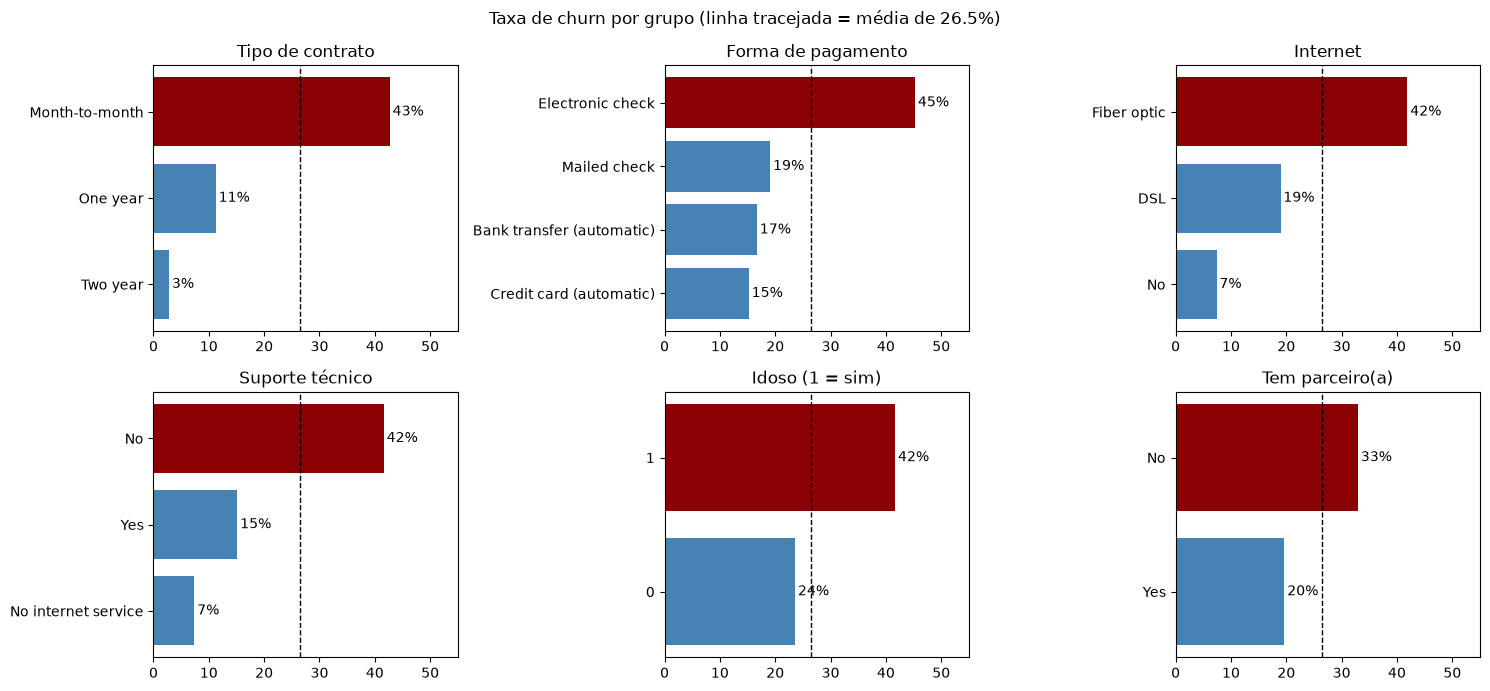

In [3]:
# Taxa de churn em cada grupo, para os fatores mais importantes
fatores = {
    "Contract": "Tipo de contrato",
    "PaymentMethod": "Forma de pagamento",
    "InternetService": "Internet",
    "TechSupport": "Suporte técnico",
    "SeniorCitizen": "Idoso (1 = sim)",
    "Partner": "Tem parceiro(a)",
}
media = dados["churn"].mean() * 100

fig, eixos = plt.subplots(2, 3, figsize=(15, 7))
for ax, (coluna, titulo) in zip(eixos.flat, fatores.items()):
    taxa = dados.groupby(coluna)["churn"].mean().sort_values() * 100
    ax.barh(taxa.index.astype(str), taxa, color=["darkred" if t > media else "steelblue" for t in taxa])
    ax.axvline(media, color="black", ls="--", lw=1)
    for i, t in enumerate(taxa):
        ax.text(t + 0.5, i, f"{t:.0f}%", va="center")
    ax.set_title(titulo)
    ax.set_xlim(0, 55)
fig.suptitle(f"Taxa de churn por grupo (linha tracejada = média de {media:.1f}%)")
plt.tight_layout()
plt.savefig("../reports/figures/churn_por_fator.png", dpi=120)
plt.show()

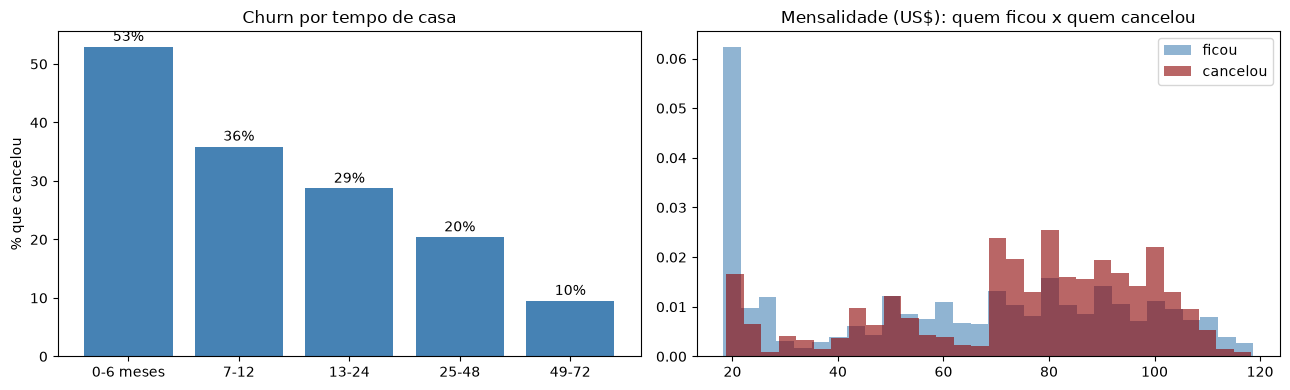

,tenure,MonthlyCharges
churn,,
ficou,37.6,61.3
cancelou,18.0,74.4


In [4]:
# Tempo de casa e mensalidade
dados["faixa_tempo"] = pd.cut(dados["tenure"], [-1, 6, 12, 24, 48, 72],
                              labels=["0-6 meses", "7-12", "13-24", "25-48", "49-72"])
por_tempo = dados.groupby("faixa_tempo", observed=True)["churn"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(por_tempo.index.astype(str), por_tempo, color="steelblue")
for i, t in enumerate(por_tempo):
    ax1.text(i, t + 1, f"{t:.0f}%", ha="center")
ax1.set_title("Churn por tempo de casa")
ax1.set_ylabel("% que cancelou")

for valor, nome, cor in [(0, "ficou", "steelblue"), (1, "cancelou", "darkred")]:
    ax2.hist(dados.loc[dados["churn"] == valor, "MonthlyCharges"], bins=30, alpha=0.6, color=cor,
             label=nome, density=True)
ax2.set_title("Mensalidade (US$): quem ficou x quem cancelou")
ax2.legend()
plt.tight_layout()
plt.savefig("../reports/figures/tempo_e_mensalidade.png", dpi=120)
plt.show()

dados.groupby("churn")[["tenure", "MonthlyCharges"]].mean().round(1).rename(index={0: "ficou", 1: "cancelou"})